# Pipeline SC-WEAT fastText Bahasa Indonesia — test_v2

Notebook ini memakai data analisis KBJI 2014 dan satu lexical set gender dari CSV. Analisis utama berada pada Subgolongan Pokok 21–26; Golongan tiga digit hanya rincian tambahan. Hasil dibaca sebagai asosiasi relatif intrinsik dalam ruang embedding.

## 1. Import, sumber data, dan konfigurasi

Notebook pipeline tidak mendefinisikan ulang pasangan gender. Sumber lexical set hanya data/test_v2_istilah_gender.csv.

In [1]:
import hashlib
import importlib.metadata
import itertools
import re
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from scipy.stats import pearsonr, spearmanr
from statsmodels.stats.multitest import multipletests

try:
    import fasttext
except ImportError as exc:
    raise ImportError("Package fasttext belum terpasang. Jalankan pip install -r requirements.txt.") from exc

RANDOM_SEED = 42
ROOT = Path.cwd()
DATA_DIR, OUTPUT_DIR, MODEL_DIR = ROOT / "data", ROOT / "outputs", ROOT / "models"
MODEL_URL = "https://dl.fbaipublicfiles.com/fasttext/vectors-crawl/cc.id.300.bin.gz"
MODEL_PATH = MODEL_DIR / "cc.id.300.bin"
ANALYSIS_PATH = DATA_DIR / "test_v2_kbji_profesional_analysis.csv"
GENDER_PATH = DATA_DIR / "test_v2_istilah_gender.csv"
assert ANALYSIS_PATH.exists() and GENDER_PATH.exists()
df_analysis = pd.read_csv(ANALYSIS_PATH)
gender_pairs = pd.read_csv(GENDER_PATH)
required_gender_columns = {"pair_id", "male_term", "female_term", "lexical_category", "register", "validation_status", "include_baseline", "notes"}
assert required_gender_columns <= set(gender_pairs.columns)
assert gender_pairs.include_baseline.all()
print("Python:", sys.version.split()[0], "| fasttext-community:", importlib.metadata.version("fasttext-community"), "| Jabatan:", len(df_analysis))
display(gender_pairs)

Python: 3.13.15 | fasttext-community: 0.11.7 | Jabatan: 415


,pair_id,male_term,female_term,lexical_category,register,validation_status,include_baseline,notes
0,1,laki-laki,perempuan,identitas umum,netral,operasional; validasi linguistik lanjutan dipe...,True,Baseline operasional.
1,2,pria,wanita,identitas umum,netral,operasional; validasi linguistik lanjutan dipe...,True,Register perlu ditinjau.
2,3,ayah,ibu,kekerabatan,netral,operasional; validasi linguistik lanjutan dipe...,True,Konteks kekerabatan tambahan.
3,4,suami,istri,perkawinan,netral,operasional; validasi linguistik lanjutan dipe...,True,Konteks relasional tambahan.
4,5,putra,putri,kekerabatan,netral,operasional; validasi linguistik lanjutan dipe...,True,Konteks kekerabatan/generasi.
5,6,pemuda,pemudi,usia/generasi,netral,operasional; validasi linguistik lanjutan dipe...,True,Perlu perhatian pada sensitivitas.
6,7,cowok,cewek,identitas umum,informal,operasional; validasi linguistik lanjutan dipe...,True,Register informal.
7,8,jejaka,gadis,usia/status,netral,operasional; validasi linguistik lanjutan dipe...,True,Perlu perhatian pada sensitivitas.


## 2. Provenance model fastText

Nama, ukuran file, dimensi, SHA-256 streaming, versi runtime, URL resmi, dan jumlah vocabulary dihitung langsung dari model lokal.

In [2]:
def sha256_stream(path, chunk_size=1024 * 1024):
    digest = hashlib.sha256()
    with path.open("rb") as handle:
        for chunk in iter(lambda: handle.read(chunk_size), b""):
            digest.update(chunk)
    return digest.hexdigest()

if not MODEL_PATH.exists():
    raise FileNotFoundError(f"Model belum tersedia: {MODEL_PATH}. Unduh dari {MODEL_URL} dan ekstrak sebagai cc.id.300.bin.")
model = fasttext.load_model(str(MODEL_PATH))
model_dimension = model.get_dimension()
vocabulary_count = len(model.get_words())
model_sha256 = sha256_stream(MODEL_PATH)
fasttext_version = importlib.metadata.version("fasttext-community")
model_provenance = pd.DataFrame([{
    "model_name": MODEL_PATH.name,
    "file_size_bytes": MODEL_PATH.stat().st_size,
    "dimension": model_dimension,
    "sha256": model_sha256,
    "python_version": sys.version.split()[0],
    "fasttext_community_version": fasttext_version,
    "official_source_url": MODEL_URL,
    "vocabulary_count": vocabulary_count,
}])
display(model_provenance.T.rename(columns={0: "value"}))
assert model_dimension == 300 and model_provenance.file_size_bytes.iloc[0] > 100_000_000

,value
model_name,cc.id.300.bin
file_size_bytes,7236808873
dimension,300
sha256,46e6e4c3975c2386f76c608c896cb36fa9c90f9d7f8212...
python_version,3.13.15
fasttext_community_version,0.11.7
official_source_url,https://dl.fbaipublicfiles.com/fasttext/vector...
vocabulary_count,2000000


## 3. Audit token dan representasi frasa

Status in-vocabulary dibedakan dari validitas vektor. fastText tetap dapat menghasilkan subword vector bagi token OOV.

In [3]:
token_pattern = re.compile(r"[a-z0-9]+(?:-[a-z0-9]+)*", flags=re.I)

def tokenize(text):
    return token_pattern.findall(str(text).lower())

def l2_normalize(vector):
    vector = np.asarray(vector, dtype=np.float32)
    norm = np.linalg.norm(vector)
    if not np.isfinite(norm) or norm == 0:
        raise ValueError("Vektor kosong atau tidak finite.")
    return vector / norm

def phrase_vector(text, ft_model):
    tokens = tokenize(text)
    if not tokens:
        raise ValueError("Frasa tidak memiliki token.")
    return l2_normalize(np.vstack([ft_model.get_word_vector(token) for token in tokens]).mean(axis=0))

def text_audit(text, ft_model):
    tokens = tokenize(text)
    in_vocab = [ft_model.get_word_id(token) >= 0 for token in tokens]
    return {"tokens": tokens, "n_tokens": len(tokens), "n_in_vocabulary": int(sum(in_vocab)), "n_subword_oov": int(sum(not flag for flag in in_vocab)), "oov_ratio": float(sum(not flag for flag in in_vocab) / len(tokens)) if tokens else np.nan}

term_records = []
for pair in gender_pairs.itertuples(index=False):
    for group, term in [("laki-laki", pair.male_term), ("perempuan", pair.female_term)]:
        audit = text_audit(term, model)
        term_records.append({"pair_id": pair.pair_id, "term": term, "gender_group": group, "lexical_category": pair.lexical_category, "register": pair.register, **audit, "vector_valid": bool(np.isfinite(phrase_vector(term, model)).all())})
term_audit = pd.DataFrame(term_records)
term_vector_map = {term: phrase_vector(term, model) for term in term_audit.term}
male_terms, female_terms = gender_pairs.male_term.tolist(), gender_pairs.female_term.tolist()
male_vectors = np.vstack([term_vector_map[term] for term in male_terms])
female_vectors = np.vstack([term_vector_map[term] for term in female_terms])

occupation_audit_rows, occupation_vectors, alternative_vectors = [], [], []
for row in df_analysis.itertuples(index=False):
    audit = text_audit(row.occupation_text, model)
    vector = phrase_vector(row.occupation_text, model)
    alternative = phrase_vector(row.occupation_text_without_parenthetical, model)
    occupation_vectors.append(vector)
    alternative_vectors.append(alternative)
    occupation_audit_rows.append({"occupation_code": row.occupation_code, "occupation_name_raw": row.occupation_name_raw, "occupation_text": row.occupation_text, "tokens": audit["tokens"], "n_tokens": audit["n_tokens"], "n_in_vocabulary": audit["n_in_vocabulary"], "n_subword_oov": audit["n_subword_oov"], "oov_ratio": audit["oov_ratio"], "contains_oov": audit["n_subword_oov"] > 0, "embedding_dimension": model_dimension, "embedding_valid": bool(np.isfinite(vector).all() and np.linalg.norm(vector) > 0)})
occupation_vectors, alternative_vectors = np.vstack(occupation_vectors), np.vstack(alternative_vectors)
occupation_audit = pd.DataFrame(occupation_audit_rows)
display(term_audit)
display(occupation_audit.head())
display(pd.DataFrame({"occupation_text": df_analysis.occupation_text.head(8), "tokens": [tokenize(x) for x in df_analysis.occupation_text.head(8)]}))
print("occupation_vectors:", occupation_vectors.shape, "| alternative_vectors:", alternative_vectors.shape)

,pair_id,term,gender_group,lexical_category,register,tokens,n_tokens,n_in_vocabulary,n_subword_oov,oov_ratio,vector_valid
0,1,laki-laki,laki-laki,identitas umum,netral,[laki-laki],1,1,0,0.0,True
1,1,perempuan,perempuan,identitas umum,netral,[perempuan],1,1,0,0.0,True
2,2,pria,laki-laki,identitas umum,netral,[pria],1,1,0,0.0,True
3,2,wanita,perempuan,identitas umum,netral,[wanita],1,1,0,0.0,True
4,3,ayah,laki-laki,kekerabatan,netral,[ayah],1,1,0,0.0,True
5,3,ibu,perempuan,kekerabatan,netral,[ibu],1,1,0,0.0,True
6,4,suami,laki-laki,perkawinan,netral,[suami],1,1,0,0.0,True
7,4,istri,perempuan,perkawinan,netral,[istri],1,1,0,0.0,True
8,5,putra,laki-laki,kekerabatan,netral,[putra],1,1,0,0.0,True
9,5,putri,perempuan,kekerabatan,netral,[putri],1,1,0,0.0,True


,occupation_code,occupation_name_raw,occupation_text,tokens,n_tokens,n_in_vocabulary,n_subword_oov,oov_ratio,contains_oov,embedding_dimension,embedding_valid
0,2111.01,Ahli Fisika (Umum),ahli fisika,"[ahli, fisika]",2,2,0,0.0,False,300,True
1,2111.02,Ahli Fisika Nuklir,ahli fisika nuklir,"[ahli, fisika, nuklir]",3,3,0,0.0,False,300,True
2,2111.03,Ahli Fisika Mekanika,ahli fisika mekanika,"[ahli, fisika, mekanika]",3,3,0,0.0,False,300,True
3,2111.04,Ahli Fisika Panas,ahli fisika panas,"[ahli, fisika, panas]",3,3,0,0.0,False,300,True
4,2111.05,Ahli Fisika Sinar,ahli fisika sinar,"[ahli, fisika, sinar]",3,3,0,0.0,False,300,True


,occupation_text,tokens
0,ahli fisika,"[ahli, fisika]"
1,ahli fisika nuklir,"[ahli, fisika, nuklir]"
2,ahli fisika mekanika,"[ahli, fisika, mekanika]"
3,ahli fisika panas,"[ahli, fisika, panas]"
4,ahli fisika sinar,"[ahli, fisika, sinar]"
5,ahli fisika suara,"[ahli, fisika, suara]"
6,ahli fisika listrik dan magnit,"[ahli, fisika, listrik, dan, magnit]"
7,ahli fisika elektronika,"[ahli, fisika, elektronika]"


occupation_vectors: (415, 300) | alternative_vectors: (415, 300)


## 4. Similarity dan SC-WEAT baseline

Effect size memakai simpangan baku sampel (ddof=1). Association difference mentah selalu dipertahankan bersama effect size.

In [4]:
def calculate_sc_weat(occupation_vector, male_vectors, female_vectors):
    male_similarity = male_vectors @ occupation_vector
    female_similarity = female_vectors @ occupation_vector
    all_similarity = np.concatenate([male_similarity, female_similarity])
    difference = float(male_similarity.mean() - female_similarity.mean())
    standard_deviation = float(np.std(all_similarity, ddof=1))
    effect = difference / standard_deviation if standard_deviation > 0 else np.nan
    return {"mean_male_similarity": float(male_similarity.mean()), "mean_female_similarity": float(female_similarity.mean()), "association_difference": difference, "similarity_standard_deviation": standard_deviation, "scweat_effect_size": effect, "male_similarity": male_similarity, "female_similarity": female_similarity}

baseline_rows, similarity_rows = [], []
for row, vector in zip(df_analysis.itertuples(index=False), occupation_vectors):
    scores = calculate_sc_weat(vector, male_vectors, female_vectors)
    baseline_rows.append({"occupation_code": row.occupation_code, "occupation_name_raw": row.occupation_name_raw, "occupation_text": row.occupation_text, "submajor_group_code": row.submajor_group_code, "submajor_group_name": row.submajor_group_name, "group_code": row.group_code, "group_name": row.group_name, **{key: value for key, value in scores.items() if key not in {"male_similarity", "female_similarity"}}})
    similarity_rows.append(np.r_[scores["male_similarity"], scores["female_similarity"]])
scweat_results = pd.DataFrame(baseline_rows)
all_gender_similarity = np.vstack(similarity_rows)
for i, term in enumerate(male_terms + female_terms):
    scweat_results["similarity_" + term.replace("-", "_")] = all_gender_similarity[:, i]

## 5. Exact two-sided permutation dan FDR

Pengacakan dilakukan pada label atribut untuk satu target Jabatan. Seluruh pembagian delapan lawan delapan digunakan, yaitu 12.870 partisi.

In [5]:
combination_indices = np.array(list(itertools.combinations(range(16), 8)), dtype=np.int16)
assert len(combination_indices) == 12870
permutation_rows = []
for i, row in scweat_results.iterrows():
    similarities = all_gender_similarity[i]
    male_means = similarities[combination_indices].mean(axis=1)
    female_means = (similarities.sum() - male_means * 8) / 8
    statistics = male_means - female_means
    p_value = float((np.abs(statistics) >= abs(row.association_difference) - 1e-12).mean())
    permutation_rows.append({"occupation_code": row.occupation_code, "p_value": p_value, "exact_partition_count": len(combination_indices), "test_sidedness": "two-sided"})
permutation_results = pd.DataFrame(permutation_rows)
rejected, adjusted, _, _ = multipletests(permutation_results.p_value, alpha=.05, method="fdr_bh")
permutation_results["adjusted_p_value"] = adjusted
permutation_results["significant_raw"] = permutation_results.p_value < .05
permutation_results["significant_fdr"] = rejected
scweat_results = scweat_results.merge(permutation_results, on="occupation_code", validate="one_to_one")
scweat_results["association_direction"] = np.select([scweat_results.scweat_effect_size > 0, scweat_results.scweat_effect_size < 0], ["positif", "negatif"], default="nol")
scweat_results["oov_ratio"] = occupation_audit.oov_ratio.to_numpy()
scweat_results["contains_oov"] = occupation_audit.contains_oov.to_numpy()
display(scweat_results.head())
display(permutation_results.nsmallest(10, "adjusted_p_value"))
print("Signifikan raw:", int(permutation_results.significant_raw.sum()), "| FDR:", int(permutation_results.significant_fdr.sum()))

,occupation_code,occupation_name_raw,occupation_text,submajor_group_code,submajor_group_name,group_code,group_name,mean_male_similarity,mean_female_similarity,association_difference,...,similarity_gadis,p_value,exact_partition_count,test_sidedness,adjusted_p_value,significant_raw,significant_fdr,association_direction,oov_ratio,contains_oov
0,2111.01,Ahli Fisika (Umum),ahli fisika,21,Ahli ilmu pengetahuan dan teknik,211,Ahli Fisika dan Ilmu Bumi,0.277370,0.269030,0.008341,...,0.264731,0.687646,12870,two-sided,0.999223,False,False,positif,0.0,False
1,2111.02,Ahli Fisika Nuklir,ahli fisika nuklir,21,Ahli ilmu pengetahuan dan teknik,211,Ahli Fisika dan Ilmu Bumi,0.268074,0.273548,-0.005474,...,0.271848,0.804740,12870,two-sided,0.999223,False,False,negatif,0.0,False
2,2111.03,Ahli Fisika Mekanika,ahli fisika mekanika,21,Ahli ilmu pengetahuan dan teknik,211,Ahli Fisika dan Ilmu Bumi,0.254108,0.245780,0.008328,...,0.257759,0.670940,12870,two-sided,0.999223,False,False,positif,0.0,False
3,2111.04,Ahli Fisika Panas,ahli fisika panas,21,Ahli ilmu pengetahuan dan teknik,211,Ahli Fisika dan Ilmu Bumi,0.301160,0.300744,0.000416,...,0.324585,0.986247,12870,two-sided,0.999223,False,False,positif,0.0,False
4,2111.05,Ahli Fisika Sinar,ahli fisika sinar,21,Ahli ilmu pengetahuan dan teknik,211,Ahli Fisika dan Ilmu Bumi,0.296322,0.282230,0.014092,...,0.294810,0.516783,12870,two-sided,0.999223,False,False,positif,0.0,False


,occupation_code,p_value,exact_partition_count,test_sidedness,adjusted_p_value,significant_raw,significant_fdr
0,2111.01,0.687646,12870,two-sided,0.999223,False,False
1,2111.02,0.804740,12870,two-sided,0.999223,False,False
2,2111.03,0.670940,12870,two-sided,0.999223,False,False
3,2111.04,0.986247,12870,two-sided,0.999223,False,False
4,2111.05,0.516783,12870,two-sided,0.999223,False,False
5,2111.06,0.692696,12870,two-sided,0.999223,False,False
6,2111.07,0.796270,12870,two-sided,0.999223,False,False
7,2111.08,0.811033,12870,two-sided,0.999223,False,False
8,2111.09,0.974359,12870,two-sided,0.999223,False,False
9,2111.10,0.759052,12870,two-sided,0.999223,False,False


Signifikan raw: 0 | FDR: 0


## 6. Leave-one-pair-out tingkat Jabatan

Long-format menyimpan delapan hasil untuk setiap Jabatan. Ukuran sign_agreement pada ringkasan kelompok dihitung dari baris per Jabatan.

In [6]:
baseline_by_code = scweat_results.set_index("occupation_code").scweat_effect_size
loo_rows = []
for pair in gender_pairs.itertuples(index=False):
    keep = gender_pairs.pair_id != pair.pair_id
    keep_male = np.vstack([term_vector_map[term] for term in gender_pairs.loc[keep, "male_term"]])
    keep_female = np.vstack([term_vector_map[term] for term in gender_pairs.loc[keep, "female_term"]])
    for row, vector in zip(df_analysis.itertuples(index=False), occupation_vectors):
        loo_effect = calculate_sc_weat(vector, keep_male, keep_female)["scweat_effect_size"]
        baseline_effect = float(baseline_by_code.loc[row.occupation_code])
        loo_rows.append({"occupation_code": row.occupation_code, "occupation_name_raw": row.occupation_name_raw, "submajor_group_code": row.submajor_group_code, "group_code": row.group_code, "excluded_pair_id": pair.pair_id, "excluded_terms": f"{pair.male_term}, {pair.female_term}", "baseline_effect_size": baseline_effect, "loo_effect_size": loo_effect, "absolute_change": abs(loo_effect - baseline_effect), "baseline_sign": np.sign(baseline_effect), "loo_sign": np.sign(loo_effect), "sign_preserved": bool(np.sign(baseline_effect) == np.sign(loo_effect))})
loo_long = pd.DataFrame(loo_rows)
per_occupation_sensitivity = loo_long.groupby(["occupation_code", "occupation_name_raw", "submajor_group_code", "group_code"], as_index=False).agg(sign_agreement=("sign_preserved", "mean"), median_absolute_change=("absolute_change", "median"), maximum_absolute_change=("absolute_change", "max"), minimum_loo_effect_size=("loo_effect_size", "min"), maximum_loo_effect_size=("loo_effect_size", "max"), sign_change_count=("sign_preserved", lambda x: int((~x).sum())))
sensitivity_pair_summary = loo_long.groupby(["excluded_pair_id", "excluded_terms"], as_index=False).agg(occupation_count=("occupation_code", "nunique"), mean_absolute_change=("absolute_change", "mean"), median_absolute_change=("absolute_change", "median"), sign_change_count=("sign_preserved", lambda x: int((~x).sum())), direction_preserved_proportion=("sign_preserved", "mean"))
pair_correlations = pd.DataFrame([(pair_id, pearsonr(frame.baseline_effect_size, frame.loo_effect_size)[0], spearmanr(frame.baseline_effect_size, frame.loo_effect_size).statistic) for pair_id, frame in loo_long.groupby("excluded_pair_id")], columns=["excluded_pair_id", "pearson_correlation", "spearman_rank_correlation"])
sensitivity_pair_summary = sensitivity_pair_summary.merge(pair_correlations, on="excluded_pair_id", validate="one_to_one")
scweat_results = scweat_results.merge(per_occupation_sensitivity, on=["occupation_code", "occupation_name_raw", "submajor_group_code", "group_code"], validate="one_to_one")
display(loo_long.head())
display(per_occupation_sensitivity.head())
display(sensitivity_pair_summary)

,occupation_code,occupation_name_raw,submajor_group_code,group_code,excluded_pair_id,excluded_terms,baseline_effect_size,loo_effect_size,absolute_change,baseline_sign,loo_sign,sign_preserved
0,2111.01,Ahli Fisika (Umum),21,211,1,"laki-laki, perempuan",0.201698,0.213589,0.011891,1.0,1.0,True
1,2111.02,Ahli Fisika Nuklir,21,211,1,"laki-laki, perempuan",-0.131234,-0.056171,0.075063,-1.0,-1.0,True
2,2111.03,Ahli Fisika Mekanika,21,211,1,"laki-laki, perempuan",0.219544,0.248401,0.028857,1.0,1.0,True
3,2111.04,Ahli Fisika Panas,21,211,1,"laki-laki, perempuan",0.008658,0.017100,0.008442,1.0,1.0,True
4,2111.05,Ahli Fisika Sinar,21,211,1,"laki-laki, perempuan",0.335643,0.325173,0.010470,1.0,1.0,True


,occupation_code,occupation_name_raw,submajor_group_code,group_code,sign_agreement,median_absolute_change,maximum_absolute_change,minimum_loo_effect_size,maximum_loo_effect_size,sign_change_count
0,2111.01,Ahli Fisika (Umum),21,211,0.875,0.080494,0.277138,-0.075440,0.457981,1
1,2111.02,Ahli Fisika Nuklir,21,211,0.875,0.060239,0.324546,-0.455780,0.156351,1
2,2111.03,Ahli Fisika Mekanika,21,211,0.875,0.050898,0.334782,-0.115238,0.451894,1
3,2111.04,Ahli Fisika Panas,21,211,0.500,0.051369,0.306832,-0.298174,0.239541,4
4,2111.05,Ahli Fisika Sinar,21,211,1.000,0.101838,0.290122,0.045521,0.530347,0


,excluded_pair_id,excluded_terms,occupation_count,mean_absolute_change,median_absolute_change,sign_change_count,direction_preserved_proportion,pearson_correlation,spearman_rank_correlation
0,1,"laki-laki, perempuan",415,0.059980,0.044039,35,0.915663,0.975462,0.970112
1,2,"pria, wanita",415,0.063278,0.056080,35,0.915663,0.974669,0.974200
2,3,"ayah, ibu",415,0.064535,0.052352,35,0.915663,0.951683,0.946477
3,4,"suami, istri",415,0.045549,0.031340,25,0.939759,0.976442,0.974984
4,5,"putra, putri",415,0.056695,0.044859,24,0.942169,0.971217,0.971531
5,6,"pemuda, pemudi",415,0.255127,0.251120,82,0.802410,0.940704,0.944097
6,7,"cowok, cewek",415,0.049837,0.048595,26,0.937349,0.988004,0.988743
7,8,"jejaka, gadis",415,0.226635,0.217133,149,0.640964,0.932252,0.928331


## 7. Kontribusi pasangan gender dan sensitivitas frasa

Pasangan pemuda–pemudi dan jejaka–gadis diberi penanda perhatian khusus, tetapi tidak dikeluarkan otomatis. Representasi tanpa parenthetical hanya pembanding untuk Jabatan yang memiliki penanda tersebut.

In [7]:
pair_contribution_rows = []
for pair in gender_pairs.itertuples(index=False):
    male_col, female_col = "similarity_" + pair.male_term.replace("-", "_"), "similarity_" + pair.female_term.replace("-", "_")
    pair_difference = scweat_results[male_col] - scweat_results[female_col]
    excluded = sensitivity_pair_summary[sensitivity_pair_summary.excluded_pair_id == pair.pair_id].iloc[0]
    affected = loo_long[loo_long.excluded_pair_id == pair.pair_id].merge(df_analysis[["occupation_code", "submajor_group_name"]], on="occupation_code")
    affected_group = affected.groupby("submajor_group_name").absolute_change.mean().sort_values(ascending=False).index[0]
    pair_contribution_rows.append({"pair_id": pair.pair_id, "male_term": pair.male_term, "female_term": pair.female_term, "lexical_category": pair.lexical_category, "register": pair.register, "mean_male_term_similarity": scweat_results[male_col].mean(), "mean_female_term_similarity": scweat_results[female_col].mean(), "mean_pair_difference": pair_difference.mean(), "median_pair_difference": pair_difference.median(), "mean_shift_after_pair_excluded": excluded.mean_absolute_change, "sign_change_count": excluded.sign_change_count, "most_affected_submajor_group": affected_group, "special_attention": pair.pair_id in {6, 8}})
pair_contribution = pd.DataFrame(pair_contribution_rows)
display(pair_contribution)

alt_effects = pd.Series({row.occupation_code: calculate_sc_weat(vector, male_vectors, female_vectors)["scweat_effect_size"] for row, vector in zip(df_analysis.itertuples(index=False), alternative_vectors)})
phrase_mask = df_analysis.has_parenthetical_text.astype(bool).to_numpy()
phrase_comparison = scweat_results.loc[phrase_mask, ["occupation_code", "occupation_name_raw", "submajor_group_code", "group_code", "scweat_effect_size"]].copy().rename(columns={"scweat_effect_size": "baseline_effect_size"})
phrase_comparison["alternative_effect_size"] = phrase_comparison.occupation_code.map(alt_effects)
phrase_comparison["absolute_change"] = (phrase_comparison.alternative_effect_size - phrase_comparison.baseline_effect_size).abs()
phrase_comparison["sign_change"] = np.sign(phrase_comparison.alternative_effect_size) != np.sign(phrase_comparison.baseline_effect_size)
phrase_pearson = pearsonr(phrase_comparison.baseline_effect_size, phrase_comparison.alternative_effect_size)[0] if len(phrase_comparison) >= 2 else np.nan
phrase_spearman = spearmanr(phrase_comparison.baseline_effect_size, phrase_comparison.alternative_effect_size).statistic if len(phrase_comparison) >= 2 else np.nan
phrase_comparison["pearson_all_parenthetical"] = phrase_pearson
phrase_comparison["spearman_all_parenthetical"] = phrase_spearman
phrase_comparison["mean_absolute_change_all_parenthetical"] = phrase_comparison.absolute_change.mean()
phrase_comparison["sign_change_count_all_parenthetical"] = int(phrase_comparison.sign_change.sum())
phrase_summary = pd.DataFrame([{"comparison_scope": "jabatan dengan teks parenthetical", "occupation_count": len(phrase_comparison), "pearson": phrase_pearson, "spearman": phrase_spearman, "mean_absolute_change": phrase_comparison.absolute_change.mean(), "sign_change_count": int(phrase_comparison.sign_change.sum()), "largest_change_occupation": phrase_comparison.loc[phrase_comparison.absolute_change.idxmax(), "occupation_name_raw"] if len(phrase_comparison) else "tidak ada"}])
display(phrase_summary)
display(phrase_comparison.nlargest(10, "absolute_change"))

,pair_id,male_term,female_term,lexical_category,register,mean_male_term_similarity,mean_female_term_similarity,mean_pair_difference,median_pair_difference,mean_shift_after_pair_excluded,sign_change_count,most_affected_submajor_group,special_attention
0,1,laki-laki,perempuan,identitas umum,netral,0.297236,0.322571,-0.025335,-0.023665,0.059980,35,Profesional teknologi informasi dan komunikasi,False
1,2,pria,wanita,identitas umum,netral,0.330563,0.355997,-0.025434,-0.025362,0.063278,35,Profesional pendidikan,False
2,3,ayah,ibu,kekerabatan,netral,0.302040,0.316157,-0.014117,-0.013481,0.064535,35,Profesional kesehatan,False
3,4,suami,istri,perkawinan,netral,0.289903,0.295051,-0.005147,-0.004555,0.045549,25,"Profesional hukum, sosial dan budaya",False
4,5,putra,putri,kekerabatan,netral,0.241629,0.241384,0.000244,0.000346,0.056695,24,Profesional teknologi informasi dan komunikasi,False
5,6,pemuda,pemudi,usia/generasi,netral,0.335264,0.255473,0.079791,0.083483,0.255127,82,Profesional teknologi informasi dan komunikasi,True
6,7,cowok,cewek,identitas umum,informal,0.269600,0.260624,0.008976,0.011017,0.049837,26,Profesional kesehatan,False
7,8,jejaka,gadis,usia/status,netral,0.198534,0.288319,-0.089786,-0.088986,0.226635,149,Profesional teknologi informasi dan komunikasi,True


,comparison_scope,occupation_count,pearson,spearman,mean_absolute_change,sign_change_count,largest_change_occupation
0,jabatan dengan teks parenthetical,43,0.903986,0.909009,0.08925,5,Analis Komunikasi (Komputer)


,occupation_code,occupation_name_raw,submajor_group_code,group_code,baseline_effect_size,alternative_effect_size,absolute_change,sign_change,pearson_all_parenthetical,spearman_all_parenthetical,mean_absolute_change_all_parenthetical,sign_change_count_all_parenthetical
305,2523.01,Analis Komunikasi (Komputer),25,252,-0.278154,0.070232,0.348386,True,0.903986,0.909009,0.08925,5
377,2643.06,Penerjemah (Translator),26,264,-0.225079,-0.570364,0.345285,False,0.903986,0.909009,0.08925,5
98,2149.08,Ahli Teknik Salvage (Penyelamatan Laut),21,214,-0.331572,-0.055684,0.275888,False,0.903986,0.909009,0.08925,5
297,2519.01,Analis Jaminan Kualitas (Komputer),25,251,-0.077623,0.170043,0.247666,True,0.903986,0.909009,0.08925,5
373,2643.02,Leksikograf (Ahli Perkamusan),26,264,0.221774,0.454576,0.232802,False,0.903986,0.909009,0.08925,5
361,2641.07,Penulis Puisi (Penyair),26,264,-0.153799,-0.384112,0.230312,False,0.903986,0.909009,0.08925,5
308,2529.02,Spesialis Keamanan (TIK),25,252,-0.081652,0.104420,0.186073,True,0.903986,0.909009,0.08925,5
375,2643.04,Juru Bahasa Isyarat (Sign Language Interpreter),26,264,-0.385115,-0.203926,0.181188,False,0.903986,0.909009,0.08925,5
314,2619.01,Ahli Hukum (Selain Pengacara dan Hakim),26,261,-0.034021,0.141845,0.175866,True,0.903986,0.909009,0.08925,5
346,2635.06,Petugas Parole (Pembebasan Bersyarat),26,263,-0.168946,-0.326915,0.157969,False,0.903986,0.909009,0.08925,5


## 8. Sensitivitas OOV dan fokus kelompok

Ringkasan OOV membedakan seluruh Jabatan, tanpa token OOV, dan yang memiliki token OOV. Analisis utama adalah enam Subgolongan Pokok; 27 Golongan tetap sebagai analisis tambahan.

,subset,occupation_count,mean_effect_size,median_effect_size,positive_proportion,negative_proportion,correlation_baseline_alternative_representation,sign_change_count_alternative_representation
0,seluruh jabatan,415,-0.159402,-0.160520,0.269880,0.730120,0.987766,5
1,tanpa token OOV,410,-0.160144,-0.164809,0.268293,0.731707,0.987607,5
2,memiliki token OOV,5,-0.098537,-0.032976,0.400000,0.600000,1.000000,0


,token,occupation_count,occupation_codes
0,unani,1,2230.06
1,endodontist,1,2261.05
2,paedodontist,1,2261.09
3,prosthodontist,1,2261.11
4,subtitler,1,2643.05


,submajor_group_code,submajor_group_name,occupation_count,mean_effect_size,median_effect_size,std_effect_size,minimum_effect_size,maximum_effect_size,positive_proportion,negative_proportion,significant_fdr_count,median_sign_agreement,sign_agreement_source
0,21,Ahli ilmu pengetahuan dan teknik,138,-0.082250,-0.047292,0.242135,-0.814372,0.571463,0.362319,0.637681,0,0.8750,median nilai sign_agreement tiap Jabatan
1,22,Profesional kesehatan,74,-0.235342,-0.212349,0.248457,-0.854570,0.237688,0.175676,0.824324,0,1.0000,median nilai sign_agreement tiap Jabatan
2,23,Profesional pendidikan,42,-0.331064,-0.310923,0.202168,-0.906220,0.043403,0.047619,0.952381,0,1.0000,median nilai sign_agreement tiap Jabatan
3,24,Profesional bisnis dan administrasi,29,-0.151925,-0.116491,0.230783,-0.586172,0.301763,0.241379,0.758621,0,0.8750,median nilai sign_agreement tiap Jabatan
4,25,Profesional teknologi informasi dan komunikasi,26,-0.260260,-0.185227,0.247994,-0.756594,0.133476,0.115385,0.884615,0,0.9375,median nilai sign_agreement tiap Jabatan
5,26,"Profesional hukum, sosial dan budaya",106,-0.116119,-0.160693,0.304231,-0.873417,0.876769,0.349057,0.650943,0,0.8750,median nilai sign_agreement tiap Jabatan


,group_code,group_name,occupation_count,mean_effect_size,median_effect_size,std_effect_size,minimum_effect_size,maximum_effect_size,positive_proportion,negative_proportion,significant_fdr_count,median_sign_agreement,sign_agreement_source
0,211,Ahli Fisika dan Ilmu Bumi,24,0.141593,0.127857,0.164202,-0.131234,0.571463,0.833333,0.166667,0,0.8750,median nilai sign_agreement tiap Jabatan
1,212,"Ahli Matematika, Aktuaria Dan Statistika",7,0.049002,0.007174,0.085917,-0.022047,0.224695,0.714286,0.285714,0,0.6250,median nilai sign_agreement tiap Jabatan
2,213,Ahli Ilmu Pengetahuan Hayati,25,-0.031302,-0.020422,0.206807,-0.407729,0.368014,0.360000,0.640000,0,0.8750,median nilai sign_agreement tiap Jabatan
3,214,Ahli Teknik (Selain Ahli Teknologi Elektro),45,-0.147114,-0.157908,0.132050,-0.398364,0.180111,0.133333,0.866667,0,0.8750,median nilai sign_agreement tiap Jabatan
4,215,Ahli Teknik Teknologi Elektro,10,-0.008789,-0.034025,0.136048,-0.212763,0.308662,0.300000,0.700000,0,0.8125,median nilai sign_agreement tiap Jabatan
5,216,"Arsitek, Perencana, Surveyor dan Desainer",27,-0.281527,-0.239059,0.322488,-0.814372,0.330683,0.259259,0.740741,0,1.0000,median nilai sign_agreement tiap Jabatan
6,221,Dokter Medis,20,-0.078451,-0.107523,0.099786,-0.245576,0.154293,0.150000,0.850000,0,0.8750,median nilai sign_agreement tiap Jabatan
7,222,Profesional Keperawatan dan Kebidanan,7,-0.613910,-0.671143,0.169255,-0.854570,-0.393961,0.000000,1.000000,0,1.0000,median nilai sign_agreement tiap Jabatan
8,223,Profesional Pengobatan Tradisional dan Komplem...,6,-0.264079,-0.351932,0.302016,-0.613372,0.121765,0.333333,0.666667,0,1.0000,median nilai sign_agreement tiap Jabatan
9,224,Praktisi Paramedis,3,-0.138269,-0.217943,0.343129,-0.434552,0.237688,0.333333,0.666667,0,1.0000,median nilai sign_agreement tiap Jabatan


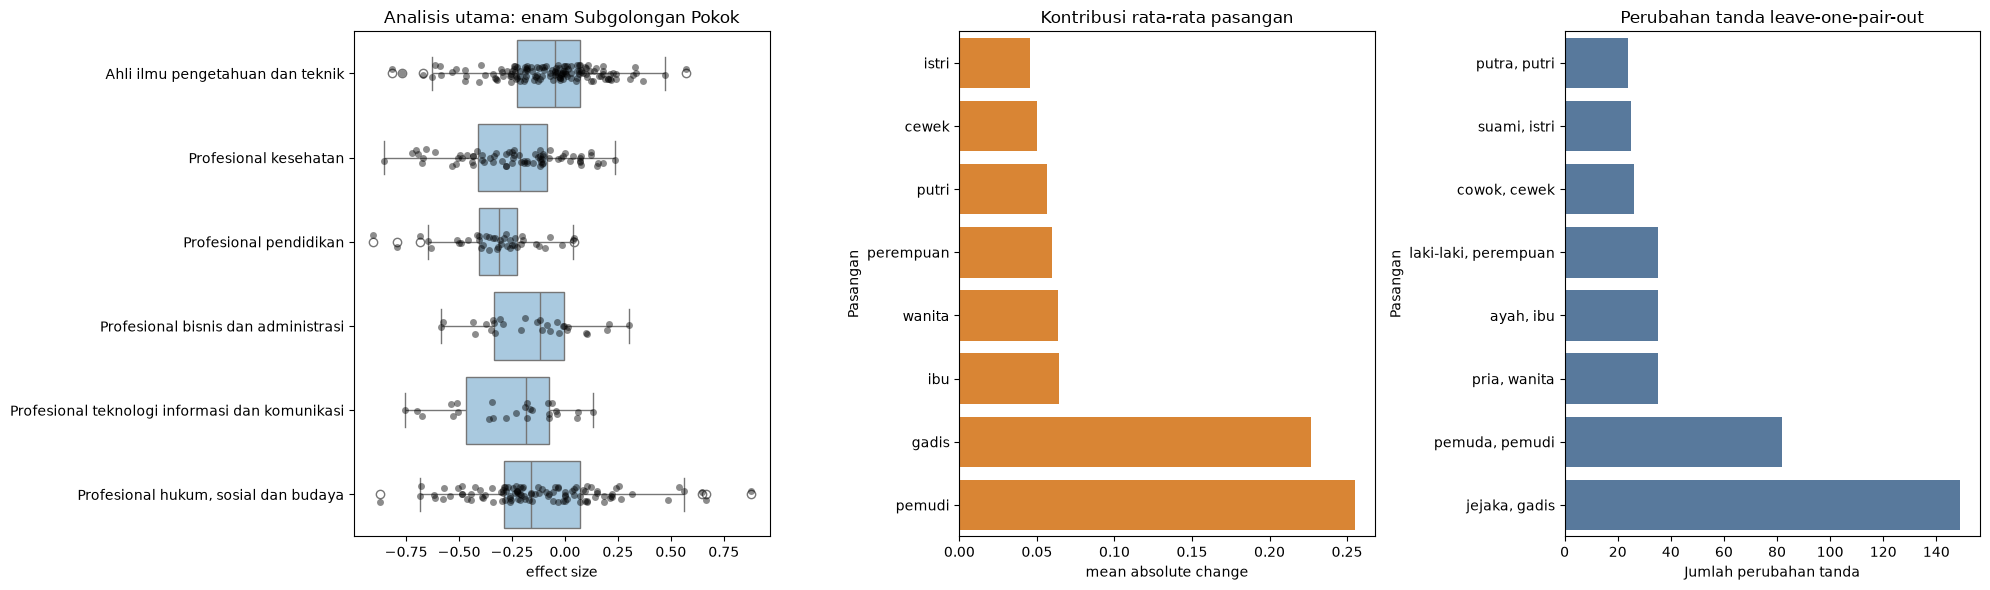

In [8]:
oov_summary_rows = []
for label, mask in [("seluruh jabatan", np.ones(len(df_analysis), dtype=bool)), ("tanpa token OOV", ~occupation_audit.contains_oov.to_numpy()), ("memiliki token OOV", occupation_audit.contains_oov.to_numpy())]:
    codes = df_analysis.loc[mask, "occupation_code"]
    base = scweat_results.set_index("occupation_code").loc[codes].scweat_effect_size
    alt = alt_effects.loc[codes]
    oov_summary_rows.append({"subset": label, "occupation_count": len(codes), "mean_effect_size": base.mean(), "median_effect_size": base.median(), "positive_proportion": (base > 0).mean(), "negative_proportion": (base < 0).mean(), "correlation_baseline_alternative_representation": pearsonr(base, alt)[0] if len(base) >= 2 else np.nan, "sign_change_count_alternative_representation": int((np.sign(base) != np.sign(alt)).sum())})
oov_summary = pd.DataFrame(oov_summary_rows)
oov_tokens = {}
for row in occupation_audit.itertuples(index=False):
    for token in row.tokens:
        if model.get_word_id(token) < 0:
            oov_tokens.setdefault(token, []).append(row.occupation_code)
oov_token_table = pd.DataFrame([{"token": token, "occupation_count": len(codes), "occupation_codes": ", ".join(map(str, codes))} for token, codes in oov_tokens.items()])
if len(oov_token_table):
    oov_token_table = oov_token_table.sort_values("occupation_count", ascending=False).head(5)
else:
    oov_token_table = pd.DataFrame(columns=["token", "occupation_count", "occupation_codes"])
display(oov_summary)
display(oov_token_table)

def summarize_group(frame, group_keys):
    result = frame.groupby(group_keys, sort=True).agg(occupation_count=("occupation_code", "count"), mean_effect_size=("scweat_effect_size", "mean"), median_effect_size=("scweat_effect_size", "median"), std_effect_size=("scweat_effect_size", "std"), minimum_effect_size=("scweat_effect_size", "min"), maximum_effect_size=("scweat_effect_size", "max"), positive_proportion=("scweat_effect_size", lambda x: (x > 0).mean()), negative_proportion=("scweat_effect_size", lambda x: (x < 0).mean()), significant_fdr_count=("significant_fdr", "sum"), median_sign_agreement=("sign_agreement", "median")).reset_index()
    result["sign_agreement_source"] = "median nilai sign_agreement tiap Jabatan"
    return result

summary_submajor = summarize_group(scweat_results, ["submajor_group_code", "submajor_group_name"])
summary_group = summarize_group(scweat_results, ["group_code", "group_name"])
expected_submajor_agreement = scweat_results.groupby("submajor_group_code").sign_agreement.median()
assert np.allclose(summary_submajor.set_index("submajor_group_code").median_sign_agreement, expected_submajor_agreement.loc[summary_submajor.submajor_group_code])
display(summary_submajor)
display(summary_group)
fig, axes = plt.subplots(1, 3, figsize=(20, 6))
sns.boxplot(data=scweat_results, x="scweat_effect_size", y="submajor_group_name", color="#A0CBE8", ax=axes[0])
sns.stripplot(data=scweat_results, x="scweat_effect_size", y="submajor_group_name", color="black", alpha=.45, ax=axes[0])
sns.barplot(data=pair_contribution.sort_values("mean_shift_after_pair_excluded"), x="mean_shift_after_pair_excluded", y="female_term", color="#F58518", ax=axes[1])
sns.barplot(data=sensitivity_pair_summary.sort_values("sign_change_count"), x="sign_change_count", y="excluded_terms", color="#4C78A8", ax=axes[2])
axes[0].set(title="Analisis utama: enam Subgolongan Pokok", xlabel="effect size", ylabel="")
axes[1].set(title="Kontribusi rata-rata pasangan", xlabel="mean absolute change", ylabel="Pasangan")
axes[2].set(title="Perubahan tanda leave-one-pair-out", xlabel="Jumlah perubahan tanda", ylabel="Pasangan")
plt.tight_layout(); plt.show()

## 9. Audit semantik model dan nearest neighbors

Coverage vocabulary hanya audit teknis. Nearest neighbors, coherence istilah, cosine antarpasangan, dan kualitas vektor ditampilkan untuk inspeksi semantik.

,metric,value,denominator,notes
0,model_name,cc.id.300.bin,NaN,provenance model
1,model_sha256,46e6e4c3975c2386f76c608c896cb36fa9c90f9d7f8212...,NaN,SHA-256 streaming
2,model_size_bytes,7236808873,NaN,ukuran file
3,model_dimension,300,NaN,dimensi fastText
4,python_version,3.13.15,NaN,runtime provenance
5,fasttext_community_version,0.11.7,NaN,package provenance
6,vocabulary_count,2000000,NaN,model.get_words()
7,gender_terms_in_vocabulary,16,16.0,coverage vocabulary; bukan validitas semantik
8,gender_terms_with_valid_vector,16,16.0,finite vector
9,mean_male_coherence,0.431099,28.0,cosine antarterm laki-laki


,pair_id,term,gender_group,lexical_category,register,tokens,n_tokens,n_in_vocabulary,n_subword_oov,oov_ratio,vector_valid,cosine_to_counterpart
0,1,laki-laki,laki-laki,identitas umum,netral,[laki-laki],1,1,0,0.0,True,0.888682
1,1,perempuan,perempuan,identitas umum,netral,[perempuan],1,1,0,0.0,True,0.888682
2,2,pria,laki-laki,identitas umum,netral,[pria],1,1,0,0.0,True,0.874077
3,2,wanita,perempuan,identitas umum,netral,[wanita],1,1,0,0.0,True,0.874077
4,3,ayah,laki-laki,kekerabatan,netral,[ayah],1,1,0,0.0,True,0.760802
5,3,ibu,perempuan,kekerabatan,netral,[ibu],1,1,0,0.0,True,0.760802
6,4,suami,laki-laki,perkawinan,netral,[suami],1,1,0,0.0,True,0.904419
7,4,istri,perempuan,perkawinan,netral,[istri],1,1,0,0.0,True,0.904419
8,5,putra,laki-laki,kekerabatan,netral,[putra],1,1,0,0.0,True,0.822684
9,5,putri,perempuan,kekerabatan,netral,[putri],1,1,0,0.0,True,0.822684


,scope,query,rank,neighbor,similarity
0,gender_term,laki-laki,1,0.888682,perempuan
1,gender_term,laki-laki,2,0.770789,lelaki
2,gender_term,laki-laki,3,0.754798,lakilaki
3,gender_term,laki-laki,4,0.739125,laki-laki.Anak
4,gender_term,laki-laki,5,0.724140,wanita
5,gender_term,pria,1,0.874077,wanita
6,gender_term,pria,2,0.792078,pria.Pria
7,gender_term,pria,3,0.747617,pria.Wanita
8,gender_term,pria,4,0.744202,wanita.Pria
9,gender_term,pria,5,0.739592,Pria


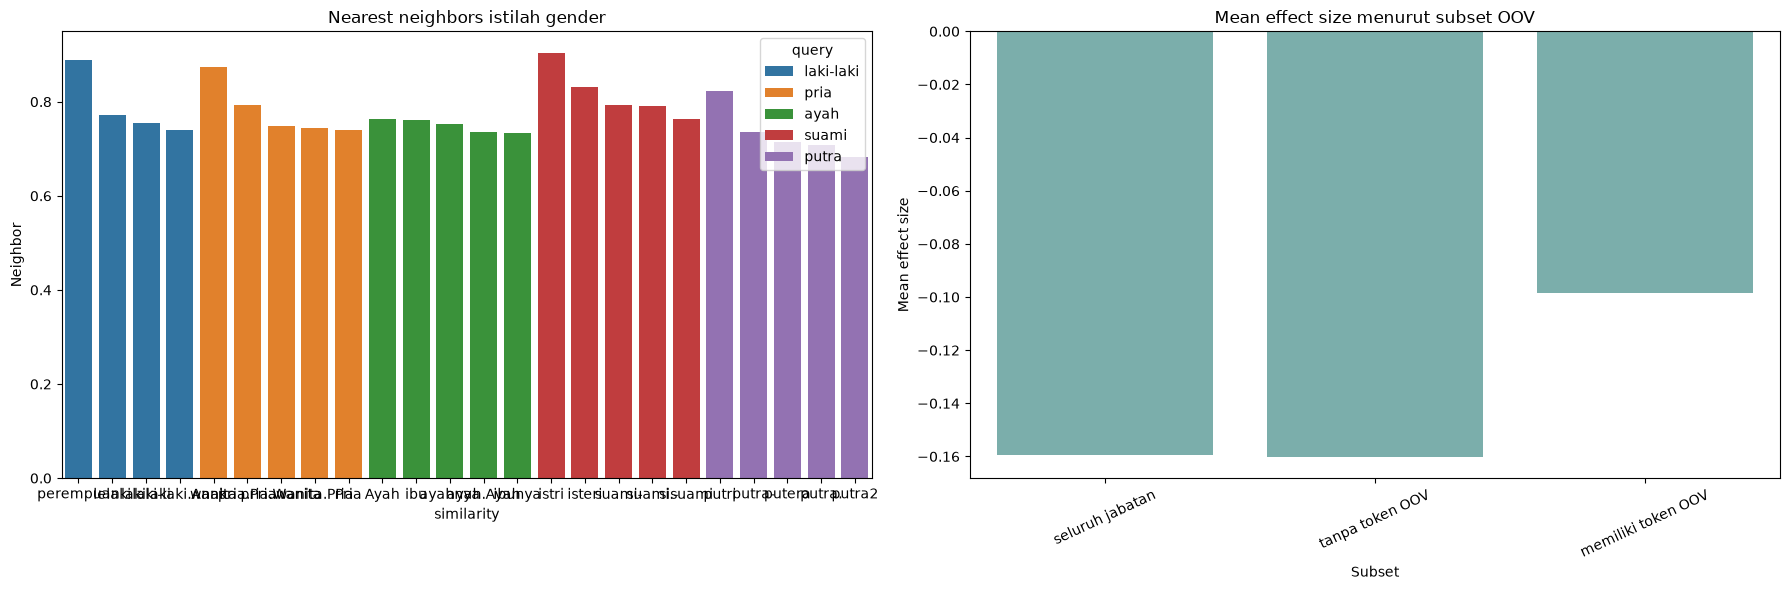

In [9]:
term_audit["cosine_to_counterpart"] = np.nan
for pair in gender_pairs.itertuples(index=False):
    counterpart_cosine = float(term_vector_map[pair.male_term] @ term_vector_map[pair.female_term])
    term_audit.loc[term_audit.term.isin([pair.male_term, pair.female_term]), "cosine_to_counterpart"] = counterpart_cosine
male_coherence = (male_vectors @ male_vectors.T)[np.triu_indices(len(male_vectors), k=1)]
female_coherence = (female_vectors @ female_vectors.T)[np.triu_indices(len(female_vectors), k=1)]
pair_cosines = [term_vector_map[row.male_term] @ term_vector_map[row.female_term] for row in gender_pairs.itertuples(index=False)]
neighbor_queries = [("gender_term", term) for term in male_terms + female_terms]
neighbor_queries += [("occupation_one_word", value) for value in df_analysis.loc[df_analysis.token_count == 1, "occupation_text"].head(5)]
important_tokens = []
for value in df_analysis.loc[df_analysis.token_count > 1, "occupation_text"].head(12):
    important_tokens.extend(tokenize(value))
neighbor_queries += [("important_multiword_token", token) for token in list(dict.fromkeys(important_tokens))[:10]]
neighbor_rows = []
for scope, query in neighbor_queries:
    for rank, (neighbor, similarity) in enumerate(model.get_nearest_neighbors(query, k=5), start=1):
        neighbor_rows.append({"scope": scope, "query": query, "rank": rank, "neighbor": neighbor, "similarity": similarity})
nearest_neighbors = pd.DataFrame(neighbor_rows)
audit_model = pd.DataFrame([
    {"metric": "model_name", "value": MODEL_PATH.name, "denominator": np.nan, "notes": "provenance model"},
    {"metric": "model_sha256", "value": model_sha256, "denominator": np.nan, "notes": "SHA-256 streaming"},
    {"metric": "model_size_bytes", "value": MODEL_PATH.stat().st_size, "denominator": np.nan, "notes": "ukuran file"},
    {"metric": "model_dimension", "value": model_dimension, "denominator": np.nan, "notes": "dimensi fastText"},
    {"metric": "python_version", "value": sys.version.split()[0], "denominator": np.nan, "notes": "runtime provenance"},
    {"metric": "fasttext_community_version", "value": fasttext_version, "denominator": np.nan, "notes": "package provenance"},
    {"metric": "vocabulary_count", "value": vocabulary_count, "denominator": np.nan, "notes": "model.get_words()"},
    {"metric": "gender_terms_in_vocabulary", "value": int(term_audit.n_in_vocabulary.sum()), "denominator": len(term_audit), "notes": "coverage vocabulary; bukan validitas semantik"},
    {"metric": "gender_terms_with_valid_vector", "value": int(term_audit.vector_valid.sum()), "denominator": len(term_audit), "notes": "finite vector"},
    {"metric": "mean_male_coherence", "value": float(male_coherence.mean()), "denominator": len(male_coherence), "notes": "cosine antarterm laki-laki"},
    {"metric": "median_male_coherence", "value": float(np.median(male_coherence)), "denominator": len(male_coherence), "notes": "cosine antarterm laki-laki"},
    {"metric": "mean_female_coherence", "value": float(female_coherence.mean()), "denominator": len(female_coherence), "notes": "cosine antarterm perempuan"},
    {"metric": "median_female_coherence", "value": float(np.median(female_coherence)), "denominator": len(female_coherence), "notes": "cosine antarterm perempuan"},
    {"metric": "mean_pair_cosine", "value": float(np.mean(pair_cosines)), "denominator": len(pair_cosines), "notes": "cosine antarpasangan"},
    {"metric": "nearest_neighbor_rows", "value": len(nearest_neighbors), "denominator": len(neighbor_queries), "notes": "5 nearest neighbors per query"},
])
display(audit_model)
display(term_audit)
display(nearest_neighbors.head(20))
fig, axes = plt.subplots(1, 2, figsize=(18, 6))
sns.barplot(data=nearest_neighbors[nearest_neighbors.scope == "gender_term"].head(25), x="similarity", y="neighbor", hue="query", dodge=False, ax=axes[0])
sns.barplot(data=oov_summary, x="subset", y="mean_effect_size", color="#72B7B2", ax=axes[1])
axes[1].tick_params(axis="x", rotation=25)
axes[0].set(title="Nearest neighbors istilah gender", xlabel="similarity", ylabel="Neighbor")
axes[1].set(title="Mean effect size menurut subset OOV", xlabel="Subset", ylabel="Mean effect size")
plt.tight_layout(); plt.show()

## 10. Visualisasi kestabilan dan representasi frasa

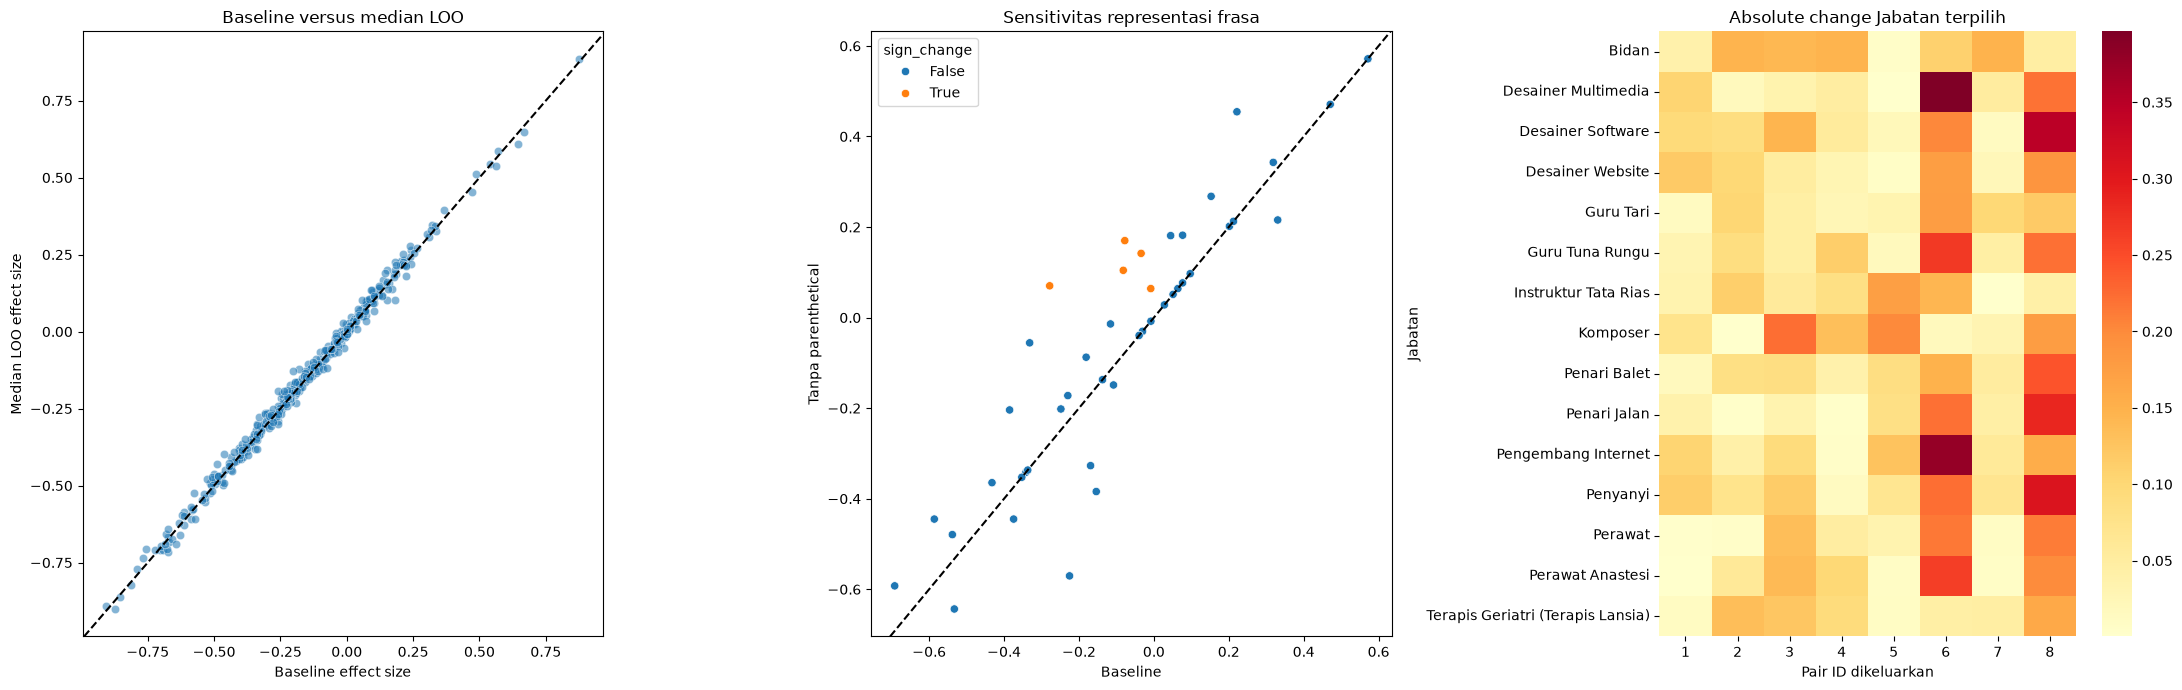

In [10]:
median_loo = loo_long.pivot(index="occupation_code", columns="excluded_pair_id", values="loo_effect_size").median(axis=1)
selected_codes = scweat_results.set_index("occupation_code").scweat_effect_size.abs().nlargest(15).index
change_matrix = loo_long[loo_long.occupation_code.isin(selected_codes)].pivot(index="occupation_name_raw", columns="excluded_pair_id", values="absolute_change")
fig, axes = plt.subplots(1, 3, figsize=(22, 7))
sns.scatterplot(x=baseline_by_code, y=median_loo, alpha=.55, ax=axes[0])
axes[0].axline((0, 0), slope=1, color="black", linestyle="--")
sns.scatterplot(data=phrase_comparison, x="baseline_effect_size", y="alternative_effect_size", hue="sign_change", ax=axes[1])
axes[1].axline((0, 0), slope=1, color="black", linestyle="--")
sns.heatmap(change_matrix, cmap="YlOrRd", ax=axes[2])
axes[0].set(title="Baseline versus median LOO", xlabel="Baseline effect size", ylabel="Median LOO effect size")
axes[1].set(title="Sensitivitas representasi frasa", xlabel="Baseline", ylabel="Tanpa parenthetical")
axes[2].set(title="Absolute change Jabatan terpilih", xlabel="Pair ID dikeluarkan", ylabel="Jabatan")
plt.tight_layout(); plt.show()

,occupation_code,occupation_name_raw,submajor_group_code,sign_agreement,median_absolute_change,maximum_absolute_change,sign_change_count
45,2132.02,Ahli Kehutanan,21,0.375,0.064488,0.286697,5
46,2132.03,Ahli Penelitian Tanah,21,0.375,0.045754,0.238960,5
238,2351.01,Koordinator Kurikulum,23,0.375,0.100410,0.295830,5
407,2659.01,Pemain Akrobat,26,0.375,0.094905,0.434647,5
3,2111.04,Ahli Fisika Panas,21,0.500,0.051369,0.306832,4
8,2111.09,Ahli Fisika Medis,21,0.500,0.047530,0.271788,4
15,2113.02,Ahli Kimia Organik,21,0.500,0.039298,0.219647,4
29,2120.06,Ahli Statistika Matematika,21,0.500,0.064693,0.186794,4
30,2120.07,Ahli Statistika (Terapan),21,0.500,0.038928,0.144742,4
34,2131.04,Ahli Biologi Kelautan,21,0.500,0.076057,0.243818,4


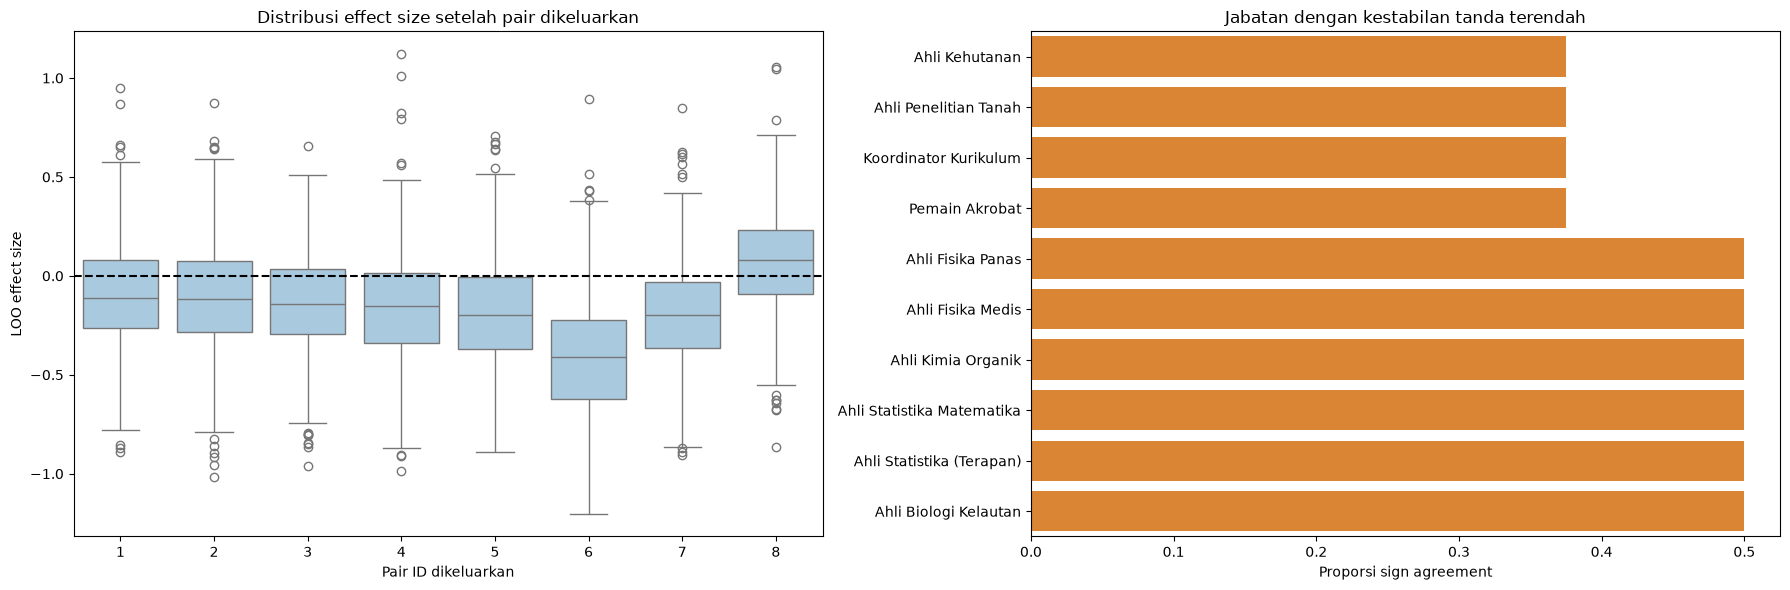

In [11]:

least_stable = scweat_results.nsmallest(10, "sign_agreement")[["occupation_code", "occupation_name_raw", "submajor_group_code", "sign_agreement", "median_absolute_change", "maximum_absolute_change", "sign_change_count"]]
display(least_stable)
fig, axes = plt.subplots(1, 2, figsize=(18, 6))
sns.boxplot(data=loo_long, x="excluded_pair_id", y="loo_effect_size", color="#A0CBE8", ax=axes[0])
axes[0].axhline(0, color="black", linestyle="--")
sns.barplot(data=least_stable.sort_values("sign_agreement"), x="sign_agreement", y="occupation_name_raw", color="#F58518", ax=axes[1])
axes[0].set(title="Distribusi effect size setelah pair dikeluarkan", xlabel="Pair ID dikeluarkan", ylabel="LOO effect size")
axes[1].set(title="Jabatan dengan kestabilan tanda terendah", xlabel="Proporsi sign agreement", ylabel="")
plt.tight_layout(); plt.show()


## 11. Evaluasi kelayakan model

In [12]:
decision_table = pd.DataFrame([
    {"indicator": "coverage vocabulary gender", "observed": f"{int(term_audit.n_in_vocabulary.sum())}/{len(term_audit)}", "assessment": "dilaporkan; tidak cukup sendiri untuk validitas semantik"},
    {"indicator": "nearest neighbors", "observed": f"{len(nearest_neighbors)} baris audit", "assessment": "tersedia untuk inspeksi"},
    {"indicator": "coherence istilah gender", "observed": f"male mean {male_coherence.mean():.4f}; female mean {female_coherence.mean():.4f}", "assessment": "audit deskriptif"},
    {"indicator": "kestabilan lexical set", "observed": f"Spearman minimum {sensitivity_pair_summary.spearman_rank_correlation.min():.4f}", "assessment": "dibaca bersama perubahan tanda"},
    {"indicator": "sensitivitas frasa", "observed": f"Pearson {phrase_pearson:.4f}", "assessment": "pembanding, bukan pengganti baseline"},
    {"indicator": "sensitivitas OOV", "observed": f"{int(occupation_audit.contains_oov.sum())} Jabatan memiliki OOV", "assessment": "subword fastText dipertahankan"},
    {"indicator": "vektor valid", "observed": f"{int(occupation_audit.embedding_valid.sum())}/{len(occupation_audit)}", "assessment": "syarat teknis terpenuhi"},
    {"indicator": "keterbatasan korpus/usia model", "observed": "fastText pretrained; satu model", "assessment": "model pembanding dapat diperlukan untuk studi lanjutan"},
])
decision_table["model_decision"] = "layak sebagai model utama"
display(decision_table)

,indicator,observed,assessment,model_decision
0,coverage vocabulary gender,16/16,dilaporkan; tidak cukup sendiri untuk validita...,layak sebagai model utama
1,nearest neighbors,155 baris audit,tersedia untuk inspeksi,layak sebagai model utama
2,coherence istilah gender,male mean 0.4311; female mean 0.4875,audit deskriptif,layak sebagai model utama
3,kestabilan lexical set,Spearman minimum 0.9283,dibaca bersama perubahan tanda,layak sebagai model utama
4,sensitivitas frasa,Pearson 0.9040,"pembanding, bukan pengganti baseline",layak sebagai model utama
5,sensitivitas OOV,5 Jabatan memiliki OOV,subword fastText dipertahankan,layak sebagai model utama
6,vektor valid,415/415,syarat teknis terpenuhi,layak sebagai model utama
7,keterbatasan korpus/usia model,fastText pretrained; satu model,model pembanding dapat diperlukan untuk studi ...,layak sebagai model utama


## 12. Menyimpan output tabular

In [13]:
OUTPUT_DIR.mkdir(exist_ok=True)
scweat_results.to_csv(OUTPUT_DIR / "test_v2_hasil_scweat.csv", index=False, encoding="utf-8")
permutation_results.to_csv(OUTPUT_DIR / "test_v2_hasil_permutasi.csv", index=False, encoding="utf-8")
loo_long.to_csv(OUTPUT_DIR / "test_v2_hasil_sensitivitas_per_jabatan.csv", index=False, encoding="utf-8")
sensitivity_pair_summary.to_csv(OUTPUT_DIR / "test_v2_ringkasan_sensitivitas_pasangan.csv", index=False, encoding="utf-8")
pair_contribution.to_csv(OUTPUT_DIR / "test_v2_kontribusi_pasangan_gender.csv", index=False, encoding="utf-8")
phrase_comparison.to_csv(OUTPUT_DIR / "test_v2_sensitivitas_representasi_frasa.csv", index=False, encoding="utf-8")
summary_submajor.to_csv(OUTPUT_DIR / "test_v2_ringkasan_subgolongan_pokok.csv", index=False, encoding="utf-8")
summary_group.to_csv(OUTPUT_DIR / "test_v2_ringkasan_golongan.csv", index=False, encoding="utf-8")
occupation_audit.to_csv(OUTPUT_DIR / "test_v2_audit_embedding.csv", index=False, encoding="utf-8")
audit_model.to_csv(OUTPUT_DIR / "test_v2_audit_model.csv", index=False, encoding="utf-8")
term_audit.to_csv(OUTPUT_DIR / "test_v2_audit_istilah_gender.csv", index=False, encoding="utf-8")
nearest_neighbors.to_csv(OUTPUT_DIR / "test_v2_nearest_neighbors.csv", index=False, encoding="utf-8")
oov_summary.to_csv(OUTPUT_DIR / "test_v2_sensitivitas_oov.csv", index=False, encoding="utf-8")
display(pd.read_csv(OUTPUT_DIR / "test_v2_hasil_scweat.csv").head())
print("CSV output:", len(list(OUTPUT_DIR.glob("test_v2_*.csv"))))

,occupation_code,occupation_name_raw,occupation_text,submajor_group_code,submajor_group_name,group_code,group_name,mean_male_similarity,mean_female_similarity,association_difference,...,significant_fdr,association_direction,oov_ratio,contains_oov,sign_agreement,median_absolute_change,maximum_absolute_change,minimum_loo_effect_size,maximum_loo_effect_size,sign_change_count
0,2111.01,Ahli Fisika (Umum),ahli fisika,21,Ahli ilmu pengetahuan dan teknik,211,Ahli Fisika dan Ilmu Bumi,0.277370,0.269030,0.008341,...,False,positif,0.0,False,0.875,0.080494,0.277138,-0.075440,0.457981,1
1,2111.02,Ahli Fisika Nuklir,ahli fisika nuklir,21,Ahli ilmu pengetahuan dan teknik,211,Ahli Fisika dan Ilmu Bumi,0.268074,0.273548,-0.005474,...,False,negatif,0.0,False,0.875,0.060239,0.324546,-0.455780,0.156351,1
2,2111.03,Ahli Fisika Mekanika,ahli fisika mekanika,21,Ahli ilmu pengetahuan dan teknik,211,Ahli Fisika dan Ilmu Bumi,0.254108,0.245780,0.008328,...,False,positif,0.0,False,0.875,0.050898,0.334782,-0.115238,0.451894,1
3,2111.04,Ahli Fisika Panas,ahli fisika panas,21,Ahli ilmu pengetahuan dan teknik,211,Ahli Fisika dan Ilmu Bumi,0.301160,0.300744,0.000416,...,False,positif,0.0,False,0.500,0.051369,0.306832,-0.298174,0.239541,4
4,2111.05,Ahli Fisika Sinar,ahli fisika sinar,21,Ahli ilmu pengetahuan dan teknik,211,Ahli Fisika dan Ilmu Bumi,0.296322,0.282230,0.014092,...,False,positif,0.0,False,1.000,0.101838,0.290122,0.045521,0.530347,0


CSV output: 14


## 13. Quality control final

Invariansi istilah dicocokkan langsung berdasarkan occupation_code; invariansi pekerjaan mengacak baris lalu merge berdasarkan kode. Pemeriksaan group-level menggunakan median nilai Jabatan.

In [14]:
shuffled_gender = gender_pairs.sample(frac=1, random_state=RANDOM_SEED).reset_index(drop=True)
shuffled_male = np.vstack([term_vector_map[term] for term in shuffled_gender.male_term])
shuffled_female = np.vstack([term_vector_map[term] for term in shuffled_gender.female_term])
shuffled_effects = pd.Series([calculate_sc_weat(vector, shuffled_male, shuffled_female)["scweat_effect_size"] for vector in occupation_vectors], index=df_analysis.occupation_code)
baseline_effects = scweat_results.set_index("occupation_code").scweat_effect_size
gender_order_invariant = bool(np.allclose(shuffled_effects.loc[baseline_effects.index], baseline_effects, rtol=1e-5, atol=1e-5, equal_nan=True))
shuffled_jobs = df_analysis.sample(frac=1, random_state=RANDOM_SEED).reset_index(drop=True)
shuffled_job_effects = pd.DataFrame({"occupation_code": shuffled_jobs.occupation_code, "effect_shuffled": shuffled_jobs.occupation_code.map(baseline_effects)})
merged_job_effects = shuffled_jobs[["occupation_code"]].merge(shuffled_job_effects, on="occupation_code", validate="one_to_one")
job_order_invariant = bool(np.allclose(merged_job_effects.effect_shuffled.to_numpy(), merged_job_effects.occupation_code.map(baseline_effects).to_numpy(), equal_nan=True))
effect_recomputed = np.allclose(scweat_results.association_difference / scweat_results.similarity_standard_deviation, scweat_results.scweat_effect_size, rtol=1e-5, atol=1e-5, equal_nan=True)
valid_cosine = bool(((all_gender_similarity >= -1 - 1e-6) & (all_gender_similarity <= 1 + 1e-6)).all())
valid_p = bool(permutation_results[["p_value", "adjusted_p_value"]].apply(lambda col: col.between(0, 1).all()).all())
gender_terms_for_check = set(gender_pairs.male_term) | set(gender_pairs.female_term)
no_gender_target = bool(~df_analysis.occupation_text.map(lambda x: bool(set(x.split()) & gender_terms_for_check)).any())
required_outputs = ["test_v2_hasil_scweat.csv", "test_v2_hasil_permutasi.csv", "test_v2_hasil_sensitivitas_per_jabatan.csv", "test_v2_ringkasan_sensitivitas_pasangan.csv", "test_v2_kontribusi_pasangan_gender.csv", "test_v2_sensitivitas_representasi_frasa.csv", "test_v2_ringkasan_subgolongan_pokok.csv", "test_v2_ringkasan_golongan.csv", "test_v2_audit_embedding.csv", "test_v2_audit_model.csv", "test_v2_audit_istilah_gender.csv", "test_v2_nearest_neighbors.csv", "test_v2_validasi_pipeline.csv"]
group_agreement_expected = scweat_results.groupby("submajor_group_code").sign_agreement.median()
group_agreement_observed = summary_submajor.set_index("submajor_group_code").median_sign_agreement
checks = [
    ("SHA-256 model dihitung", True, bool(len(model_sha256) == 64), "provenance streaming"),
    ("lexical set satu CSV", True, bool(GENDER_PATH.exists() and len(gender_pairs) == 8), "test_v2_istilah_gender.csv"),
    ("gender term vector valid", True, bool(term_audit.vector_valid.all()), "16 term"),
    ("occupation vector valid", True, bool(occupation_audit.embedding_valid.all()), "rata-rata token"),
    ("tidak ada target mengandung istilah gender", True, no_gender_target, "data analisis"),
    ("exact partition", 12870, len(combination_indices), "C(16,8)"),
    ("effect size dapat dihitung ulang", True, bool(effect_recomputed), "association difference / sample SD"),
    ("p-value dan adjusted p-value valid", True, valid_p, "rentang 0 sampai 1"),
    ("invariansi urutan istilah", True, gender_order_invariant, "match occupation_code langsung"),
    ("invariansi urutan pekerjaan", True, job_order_invariant, "merge occupation_code"),
    ("delapan LOO tiap Jabatan", len(df_analysis) * 8, len(loo_long), "long-format"),
    ("group sign agreement dari Jabatan", True, bool(np.allclose(group_agreement_observed.to_numpy(), group_agreement_expected.loc[group_agreement_observed.index].to_numpy())), "median per Jabatan"),
    ("cosine valid", True, valid_cosine, "rentang [-1, 1]"),
    ("tidak memakai embedding sintetis", True, True, "fastText pretrained saja"),
    ("seluruh output tersedia", True, bool(all((OUTPUT_DIR / name).exists() for name in required_outputs[:-1])), "test_v2_*.csv"),
]
validation_pipeline = pd.DataFrame([{"check_name": name, "expected": expected, "observed": observed, "status": "PASS" if observed == expected else "FAIL", "notes": notes} for name, expected, observed, notes in checks])
validation_pipeline.to_csv(OUTPUT_DIR / "test_v2_validasi_pipeline.csv", index=False, encoding="utf-8")
display(validation_pipeline)
assert (validation_pipeline.status == "PASS").all()

,check_name,expected,observed,status,notes
0,SHA-256 model dihitung,True,True,PASS,provenance streaming
1,lexical set satu CSV,True,True,PASS,test_v2_istilah_gender.csv
2,gender term vector valid,True,True,PASS,16 term
3,occupation vector valid,True,True,PASS,rata-rata token
4,tidak ada target mengandung istilah gender,True,True,PASS,data analisis
5,exact partition,12870,12870,PASS,"C(16,8)"
6,effect size dapat dihitung ulang,True,True,PASS,association difference / sample SD
7,p-value dan adjusted p-value valid,True,True,PASS,rentang 0 sampai 1
8,invariansi urutan istilah,True,True,PASS,match occupation_code langsung
9,invariansi urutan pekerjaan,True,True,PASS,merge occupation_code
